In [1]:
import numpy as np
import matplotlib.pyplot as plt
import h5py
import time
import random
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
import seaborn as sns
from sklearn.metrics import confusion_matrix

In [2]:
with h5py.File('mnist_traindata.hdf5', 'r') as file:
    x_train = torch.tensor(file["xdata"][:], dtype=torch.float32)
    y_train = torch.tensor(file["ydata"][:], dtype=torch.float32)
    y_train = torch.argmax(y_train, dim=1)   
    
with h5py.File('mnist_testdata.hdf5', 'r') as file:
    x_test = torch.tensor(file["xdata"][:], dtype=torch.float32)
    y_test = torch.tensor(file["ydata"][:], dtype=torch.float32)
    y_test = torch.argmax(y_test, dim=1)  

train_loader = DataLoader(TensorDataset(x_train, y_train), batch_size=100, shuffle=True)

In [3]:
model = torch.nn.Sequential(
    nn.Linear(in_features=28*28, out_features=128),
    nn.ReLU(),
    nn.Linear(in_features=128, out_features=10)
)

In [4]:
train_losses, train_accs = [], []
test_losses, test_accs = [], []

opt = optim.SGD(model.parameters(), lr=0.1, weight_decay=1e-5)
loss_func = nn.CrossEntropyLoss()

In [5]:
model.eval()

with torch.no_grad():
    # Forward Pass Train
    output = model(x_train)
    y_pred = torch.max(output, 1)[1]
    train_loss = loss_func(output, y_train).item()
    train_losses.append(train_loss)
    train_acc = 100 * (y_pred == y_train).sum().item() / len(y_train)
    train_accs.append(train_acc)

    # Forward Pass Test
    output = model(x_test)
    y_pred = torch.max(output, 1)[1]
    test_loss = loss_func(output, y_test).item()
    test_losses.append(test_loss)
    test_acc = 100 * (y_pred == y_test).sum().item() / len(y_test)
    test_accs.append(test_acc)

model.train()

Sequential(
  (0): Linear(in_features=784, out_features=128, bias=True)
  (1): ReLU()
  (2): Linear(in_features=128, out_features=10, bias=True)
)

In [6]:
for epoch in range(50):    
    for x, y in train_loader:
        input = x.view(-1, 28*28)

        # Forward Pass
        output = model(input)

        # Loss + L1 Regularization
        loss = loss_func(output, y) + 1e-5 * sum(p.abs().sum() for p in model.parameters())

        # Backprop
        opt.zero_grad()
        loss.backward()
        
        # Optimize
        opt.step()
    
    model.eval()

    with torch.no_grad():
        # Forward Pass Train
        output = model(x_train)
        y_pred = torch.max(output, 1)[1]
        train_loss = loss_func(output, y_train).item()
        train_losses.append(train_loss)
        train_acc = 100 * (y_pred == y_train).sum().item() / len(y_train)
        train_accs.append(train_acc)
    
        # Forward Pass Test
        output = model(x_test)
        y_pred = torch.max(output, 1)[1]
        test_loss = loss_func(output, y_test).item()
        test_losses.append(test_loss)
        test_acc = 100 * (y_pred == y_test).sum().item() / len(y_test)
        test_accs.append(test_acc)

    print(f'Epoch: {epoch+1:02d}; Train Loss: {train_loss:.4f}, Train Accuracy: {train_acc:2.3f}% Test Loss: {test_loss:.4f}, Test Accuracy: {test_acc:2.3f}%')
    
    model.train()

Epoch: 01; Train Loss: 0.3041, Train Accuracy: 91.322% Test Loss: 0.2922, Test Accuracy: 91.790%
Epoch: 02; Train Loss: 0.2386, Train Accuracy: 93.222% Test Loss: 0.2360, Test Accuracy: 93.160%
Epoch: 03; Train Loss: 0.1933, Train Accuracy: 94.637% Test Loss: 0.1934, Test Accuracy: 94.440%
Epoch: 04; Train Loss: 0.1695, Train Accuracy: 95.197% Test Loss: 0.1714, Test Accuracy: 95.020%
Epoch: 05; Train Loss: 0.1414, Train Accuracy: 95.972% Test Loss: 0.1478, Test Accuracy: 95.660%
Epoch: 06; Train Loss: 0.1253, Train Accuracy: 96.517% Test Loss: 0.1339, Test Accuracy: 96.130%
Epoch: 07; Train Loss: 0.1089, Train Accuracy: 97.035% Test Loss: 0.1180, Test Accuracy: 96.690%
Epoch: 08; Train Loss: 0.0988, Train Accuracy: 97.273% Test Loss: 0.1104, Test Accuracy: 96.860%
Epoch: 09; Train Loss: 0.0907, Train Accuracy: 97.522% Test Loss: 0.1035, Test Accuracy: 96.900%
Epoch: 10; Train Loss: 0.0816, Train Accuracy: 97.778% Test Loss: 0.0977, Test Accuracy: 97.110%
Epoch: 11; Train Loss: 0.0755,

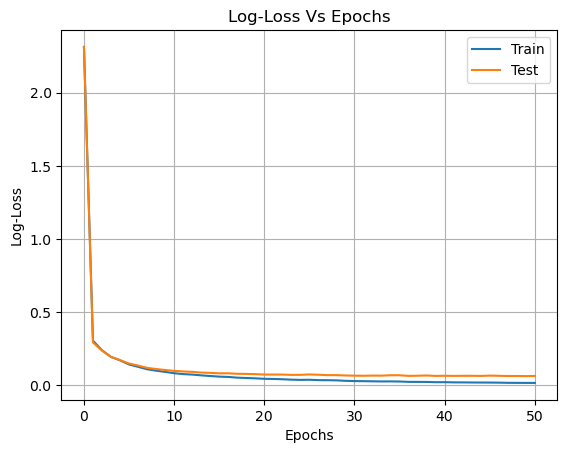

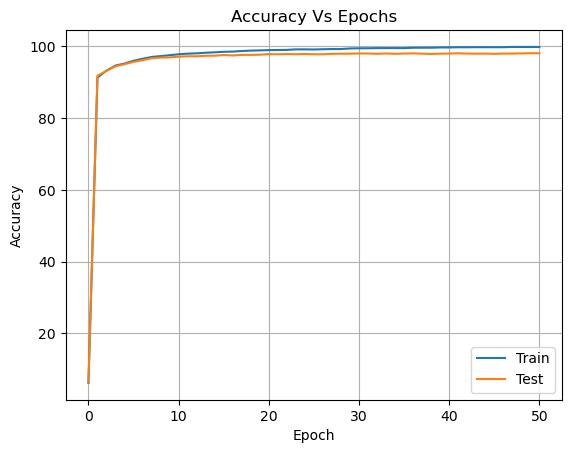

In [7]:
plt.figure()
plt.plot(train_losses, label='Train')
plt.plot(test_losses, label='Test')
plt.xlabel('Epochs')
plt.ylabel('Log-Loss')
plt.title('Log-Loss Vs Epochs')
plt.legend()
plt.grid(True)
plt.show()

plt.figure()
plt.plot(train_accs, label='Train')
plt.plot(test_accs, label='Test')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('Accuracy Vs Epochs')
plt.legend()
plt.grid(True)
plt.show()

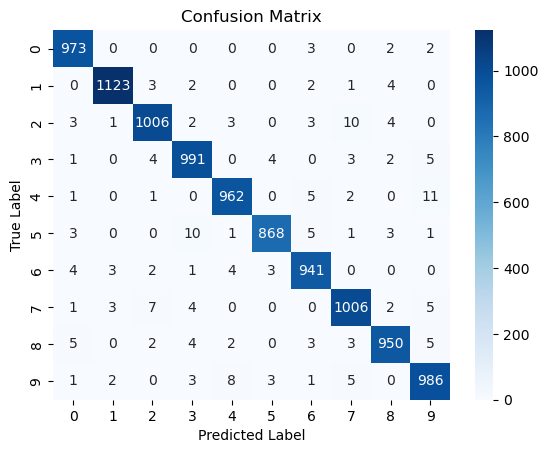

In [8]:
cm = confusion_matrix(y_test, y_pred)

plt.figure()
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=np.arange(10), yticklabels=np.arange(10))
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix')
plt.show()